# Rețele neuronale și deep learning — Cursul 10: Învățarea prin întărire: tranzacționare, acoperirea riscului și dispecerizarea bateriilor
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București (ASE); Academia Română, Institutul de Prognoză Economică (IPE)

[Deschide în Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L10_notebook_ro.ipynb)

Acest notebook reproduce cifrele și graficele cursului pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe slide-uri.

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Datele: prețurile pentru ziua următoare din România și diferența zilnică

In [3]:
import torch, torch.nn as nn
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
END = '2026-10-31'                                  # last complete month of the course data
x = x.loc[:END + ' 23:59']
x['day'] = x.index.tz_localize(None).normalize(); x['hour'] = x.index.hour

def day_matrix(zone):
    # delivery days (CET) x 24 hours; only days with 24 reported hours
    d = x[['day', 'hour', zone]].dropna()
    n = d.groupby('day')[zone].count()
    return d[d.day.isin(n[n == 24].index)].pivot_table(index='day', columns='hour', values=zone).sort_index()

RO = day_matrix('RO')
print(RO.index.min().date(), RO.index.max().date(), len(RO), 'complete days')

2015-01-02 2026-10-31 4292 complete days


day
2015     33.6
2016     28.1
2017     49.8
2018     45.7
2019     47.9
2020     35.2
2021     94.6
2022    234.1
2023    127.2
2024    188.4
2025    164.3
2026    182.8
dtype: float64


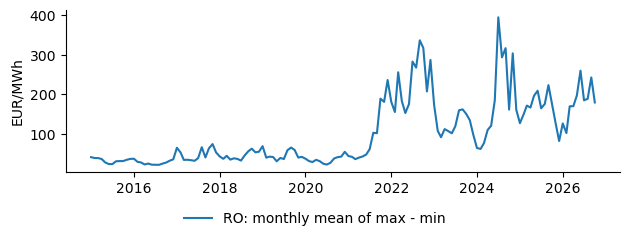

In [4]:
spread = (RO.max(axis=1) - RO.min(axis=1))
print(spread.groupby(spread.index.year).mean().round(1))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.plot(spread.resample('MS').mean(), label='RO: monthly mean of max - min')
ax.set_ylabel('EUR/MWh'); fig.legend(loc='lower center'); fig.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

## §2 Programarea dinamică: bateria cu previziune perfectă

In [5]:
E_MAX, ETA = 2, 0.85                 # 2 MWh, 1 MWh of stored energy per hour, 85 % round-trip efficiency
ETA_C = ETA_D = np.sqrt(ETA)
ACTS = np.array([-1, 0, 1])          # charge, idle, discharge

def reward(p, a):
    return np.where(a > 0, ETA_D * p, np.where(a < 0, -p / ETA_C, 0.0))

def dp_days(P):
    # backward induction V_h(s) = max_a { r(p_h, a) + V_{h+1}(s - a) }, all days at once
    D = P.shape[0]
    V = np.zeros((D, 25, E_MAX + 1)); A = np.zeros((D, 24, E_MAX + 1), dtype=int)
    for h in range(23, -1, -1):
        best = np.full((D, E_MAX + 1), -np.inf); arg = np.zeros((D, E_MAX + 1), dtype=int)
        for s in range(E_MAX + 1):
            for a in ACTS:
                if 0 <= s - a <= E_MAX:
                    q = reward(P[:, h], a) + V[:, h + 1, s - a]
                    b = q > best[:, s]; best[b, s] = q[b]; arg[b, s] = a
        V[:, h] = best; A[:, h] = arg
    return V, A

In [6]:
V, A = dp_days(RO.values)
rev = pd.Series(V[:, 0, 0], index=RO.index)
print('perfect-foresight revenue per year (thousand EUR):')
print((rev.groupby(rev.index.year).sum() / 1000).round(1))

perfect-foresight revenue per year (thousand EUR):
day
2015     20.4
2016     16.9
2017     30.1
2018     27.3
2019     28.4
2020     21.5
2021     58.8
2022    150.2
2023     85.4
2024    125.4
2025    111.2
2026     98.5
dtype: float64


In [7]:
day = (RO.loc['2026'].max(axis=1) - RO.loc['2026'].min(axis=1)).idxmax(); di = RO.index.get_loc(day)
s, plan = 0, []
for h in range(24):
    a = int(A[di, h, s]); plan.append(a); s -= a
print(day.date(), 'revenue', round(V[di, 0, 0]), 'EUR; plan:', plan)
print('value of the stored energy at noon (EUR per MWh):', round((V[di, 12, 2] - V[di, 12, 0]) / 2, 2))

2026-06-30 revenue 1541 EUR; plan: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -1, -1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0]
value of the stored energy at noon (EUR per MWh): 109.38


## §3 Q-learning tabelar cu prețurile de ieri

In [8]:
P = RO.values; days = RO.index
ok = np.array([i >= 7 and (days[i] - days[i-1]).days == 1 and (days[i] - days[i-7]).days == 7 for i in range(len(days))])
iTR = np.where(ok & (days.year >= 2019) & (days.year <= 2023))[0]
iVA = np.where(ok & (days.year == 2024))[0]
iTE = np.where(ok & (days.year >= 2025))[0]
QB = P.argsort(1).argsort(1) // 6           # quartile of each hour's price within its day
def mask_of(s):
    m = np.ones((len(s), 3), bool); m[:, 0] = s < E_MAX; m[:, 2] = s > 0; return m
def greedy_q(Q, idx):
    s = np.zeros(len(idx), int); tot = np.zeros(len(idx)); B = QB[idx - 1]
    for h in range(24):
        q = Q[h, B[:, h], s].copy(); q[~mask_of(s)] = -np.inf; a = ACTS[q.argmax(1)]
        tot += reward(P[idx, h], a); s = s - a
    return tot
rng = np.random.default_rng(SEED); Q = np.zeros((24, 4, E_MAX + 1, 3)); best = (-np.inf, None)
for ep in range(15):
    eps = max(0.05, 1 - ep / 9)
    for d in rng.permutation(iTR):
        s, b = 0, QB[d - 1]
        for h in range(24):
            feas = [k for k, a in enumerate(ACTS) if 0 <= s - a <= E_MAX]
            k = feas[rng.integers(len(feas))] if rng.random() < eps else feas[int(np.argmax(Q[h, b[h], s, feas]))]
            r_ = float(reward(P[d, h], ACTS[k])) / 100; s2 = s - ACTS[k]
            tgt = r_ if h == 23 else r_ + Q[h + 1, b[h + 1], s2, [j for j, a2 in enumerate(ACTS) if 0 <= s2 - a2 <= E_MAX]].max()
            Q[h, b[h], s, k] += 0.05 * (tgt - Q[h, b[h], s, k]); s = s2
    va = greedy_q(Q, iVA).mean()
    if va > best[0]: best = (va, Q.copy())
Q = best[1]; V, _ = dp_days(P)
q_te = greedy_q(Q, iTE)
print('test revenue, Q-learning (thousand EUR):', round(q_te.sum() / 1000, 1), '| perfect foresight:', round(V[iTE, 0, 0].sum() / 1000, 1))
print('capture ratio (%):', round(100 * q_te.sum() / V[iTE, 0, 0].sum(), 1))

test revenue, Q-learning (thousand EUR): 111.9 | perfect foresight: 202.1
capture ratio (%): 55.4


## §4 Rețeaua Q profundă dublă (DQN)

In [9]:
def zz(v): return (v - v.mean()) / (v.std() + 1.0)
FEAT = {d: np.concatenate([zz(P[d-1]), zz(P[d-7]), np.eye(7)[days[d].dayofweek]]) for d in np.concatenate([iTR, iVA, iTE])}
def obs(dl, h, s):
    return np.concatenate([np.stack([FEAT[d] for d in dl]), np.tile(np.eye(24)[h], (len(dl), 1)), np.eye(E_MAX + 1)[s]], 1).astype(np.float32)
d_in = obs(iTR[:1], 0, np.zeros(1, int)).shape[1]
mk = lambda: nn.Sequential(nn.Linear(d_in, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 3))
torch.manual_seed(SEED); net, tgt = mk(), mk(); tgt.load_state_dict(net.state_dict())
opt = torch.optim.Adam(net.parameters(), lr=5e-4)
def greedy(idx):
    s = np.zeros(len(idx), int); tot = np.zeros(len(idx))
    with torch.no_grad():
        for h in range(24):
            q = net(torch.from_numpy(obs(idx, h, s))).numpy(); q[~mask_of(s)] = -1e9
            a = ACTS[q.argmax(1)]; tot += reward(P[idx, h], a); s = s - a
    return tot
buf = []; best = (-np.inf, None)
for ep in range(20):
    eps = max(0.05, 1 - ep / 12); s = np.zeros(len(iTR), int)
    for h in range(24):
        o = obs(iTR, h, s); m = mask_of(s)
        with torch.no_grad(): q = net(torch.from_numpy(o)).numpy()
        q[~m] = -1e9; k = q.argmax(1); rnd = rng.random(len(iTR)) < eps
        k[rnd] = (rng.random((rnd.sum(), 3)) * m[rnd]).argmax(1); a = ACTS[k]; s2 = s - a
        buf.append((o, k, reward(P[iTR, h], a) / 100, obs(iTR, min(h + 1, 23), s2), mask_of(s2), np.full(len(iTR), h == 23)))
        buf = buf[-96:]; s = s2
        O, K, R, O2, M2, DN = (np.concatenate(z) for z in zip(*buf))
        for _ in range(6):
            j = rng.integers(0, len(O), 512)
            with torch.no_grad():
                q2 = net(torch.from_numpy(O2[j])); q2[torch.from_numpy(~M2[j])] = -1e9
                y = torch.from_numpy(R[j].astype(np.float32)) + tgt(torch.from_numpy(O2[j])).gather(1, q2.argmax(1, keepdim=True)).squeeze(1) * torch.from_numpy(~DN[j]).float()
            loss = nn.functional.smooth_l1_loss(net(torch.from_numpy(O[j])).gather(1, torch.from_numpy(K[j]).long()[:, None]).squeeze(1), y)
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                for pt, pn in zip(tgt.parameters(), net.parameters()): pt.mul_(0.99).add_(0.01 * pn)
    va = greedy(iVA).mean()
    if va > best[0]: best = (va, {k_: v.clone() for k_, v in net.state_dict().items()})
net.load_state_dict(best[1]); d_te = greedy(iTE)
print('test revenue, DQN (thousand EUR):', round(d_te.sum() / 1000, 1), '| capture ratio (%):', round(100 * d_te.sum() / V[iTE, 0, 0].sum(), 1))

test revenue, DQN (thousand EUR): 75.2 | capture ratio (%): 37.2


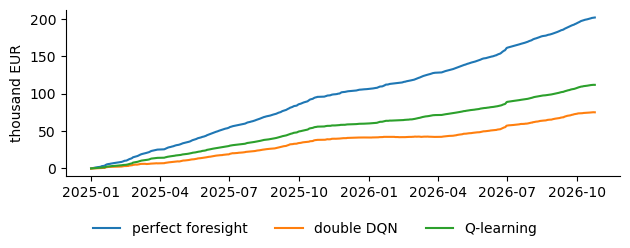

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.plot(days[iTE], np.cumsum(V[iTE, 0, 0]) / 1000, label='perfect foresight')
ax.plot(days[iTE], np.cumsum(d_te) / 1000, label='double DQN')
ax.plot(days[iTE], np.cumsum(q_te) / 1000, label='Q-learning')
ax.set_ylabel('thousand EUR'); fig.legend(loc='lower center', ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

## §5 PPO pentru tranzacționarea indicelui S&P 500

In [11]:
m = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
w = m.pivot(index='date', columns='ticker', values='close').loc[:END]
px = w['SP500'].dropna(); vix = w['VIX'].reindex(px.index).ffill()
lr = np.log(px).diff()
F = pd.DataFrame({'r1': lr, 'r5': np.log(px).diff(5), 'r21': np.log(px).diff(21), 'r63': np.log(px).diff(63),
                  'rv21': lr.rolling(21).std() * np.sqrt(252), 'vix': vix / 100, 'ma200': px / px.rolling(200).mean() - 1}).dropna()
fwd = lr.shift(-1).reindex(F.index); F, fwd = F.iloc[:-1], fwd.iloc[:-1]
tr, va, te = F.index.year <= 2016, (F.index.year >= 2017) & (F.index.year <= 2019), F.index.year >= 2020
X = ((F - F[tr].mean()) / F[tr].std()).values.astype(np.float32); RET = fwd.values.astype(np.float32); COST = 0.0005
def perf(pos, ret):
    pos = np.asarray(pos, float); return pos * ret - COST * np.abs(np.diff(np.concatenate([[0.], pos])))
def sharpe(x): return x.mean() / x.std() * np.sqrt(252)
print(F.index[te][0].date(), F.index[te][-1].date())

2020-01-02 2026-10-29


In [12]:
class AC(nn.Module):
    def __init__(s, d):
        super().__init__(); s.b = nn.Sequential(nn.Linear(d, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh())
        s.pi = nn.Linear(64, 2); s.v = nn.Linear(64, 1)
    def forward(s, x):
        h = s.b(x); return s.pi(h), s.v(h).squeeze(-1)
def run(net, idx):
    pos, prev = [], 0.
    with torch.no_grad():
        for i in idx:
            a = int(net(torch.from_numpy(np.append(X[i], prev).astype(np.float32)))[0].argmax()); pos.append(a); prev = float(a)
    return np.array(pos)
torch.manual_seed(SEED); ac = AC(X.shape[1] + 1); opt = torch.optim.Adam(ac.parameters(), lr=3e-4)
itr, iva, ite = np.where(tr)[0], np.where(va)[0], np.where(te)[0]; B, Tn = 64, 126; best = (-np.inf, None)
for it in range(60):
    st = rng.choice(itr[:-Tn], B); prev = np.zeros(B, np.float32); O, A_, LP, R, V_ = [], [], [], [], []
    with torch.no_grad():
        for t in range(Tn):
            o = torch.from_numpy(np.concatenate([X[st + t], prev[:, None]], 1).astype(np.float32)); lg, v = ac(o)
            dist = torch.distributions.Categorical(logits=lg); a = dist.sample(); pos = a.numpy().astype(np.float32)
            R.append(torch.from_numpy(100 * (pos * RET[st + t] - COST * np.abs(pos - prev)))); O.append(o); A_.append(a); LP.append(dist.log_prob(a)); V_.append(v); prev = pos
        O, A_, LP, R, V_ = map(torch.stack, (O, A_, LP, R, V_)); adv = torch.zeros_like(R); g = torch.zeros(B)
        for t in range(Tn - 1, -1, -1):
            vn = V_[t + 1] if t + 1 < Tn else torch.zeros(B)
            g = R[t] + 0.99 * vn - V_[t] + 0.99 * 0.95 * g; adv[t] = g
        ret = adv + V_
    O, A_, LP, adv, ret = (z.reshape(Tn * B, *z.shape[2:]) for z in (O, A_, LP, adv, ret)); adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    for _ in range(4):
        for b in torch.from_numpy(rng.permutation(Tn * B)).split(1024):
            lg, v = ac(O[b]); dist = torch.distributions.Categorical(logits=lg); rho = torch.exp(dist.log_prob(A_[b]) - LP[b])
            loss = -torch.min(rho * adv[b], rho.clamp(0.8, 1.2) * adv[b]).mean() + 0.5 * ((v - ret[b]) ** 2).mean() - 0.01 * dist.entropy().mean()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
    if it % 5 == 4:
        sv = sharpe(perf(run(ac, iva), RET[iva]))
        if sv > best[0]: best = (sv, {k_: v.clone() for k_, v in ac.state_dict().items()})
ac.load_state_dict(best[1]); pos = run(ac, ite)
bh = perf(np.ones(len(ite)), RET[ite]); ma = perf((F['ma200'].values[ite] > 0).astype(float), RET[ite]); pp = perf(pos, RET[ite])
print('test Sharpe  buy-and-hold', round(sharpe(bh), 2), '| MA rule', round(sharpe(ma), 2), '| PPO (one seed)', round(sharpe(pp), 2))
print('PPO share of days invested (%):', round(100 * pos.mean()))

test Sharpe  buy-and-hold 0.61 | MA rule 0.68 | PPO (one seed) 0.72
PPO share of days invested (%): 90


## §6 Acoperirea neuronală a unei opțiuni call pe o lună

In [13]:
from scipy.stats import norm
S = px; VX = vix / 100; n = 21; lS = np.log(S.values)
st = np.arange(len(S) - n); paths = np.stack([np.exp(lS[i:i + n + 1] - lS[i]) for i in st]).astype(np.float32)
vols = np.stack([VX.values[i:i + n + 1] for i in st]).astype(np.float32); y0 = S.index[st].year
TAU = (n - np.arange(n + 1)) / 252
def bs(Sx, sg, tau):
    d1 = (np.log(Sx) + 0.5 * sg**2 * tau) / (sg * np.sqrt(tau)); return Sx * norm.cdf(d1) - norm.cdf(d1 - sg * np.sqrt(tau)), norm.cdf(d1)
prem = bs(1.0, vols[:, 0], TAU[0])[0]; payoff = np.maximum(paths[:, -1] - 1, 0); C = 0.001
def es(l, a=0.95): return l[l >= np.quantile(l, a)].mean()
bsd = np.stack([bs(paths[:, k], vols[:, k], TAU[k])[1] for k in range(n)], 1)
itr, ite = np.where(y0 <= 2016)[0], np.where(y0 >= 2020)[0]
net = nn.Sequential(nn.Linear(4, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1)); wv = torch.zeros(1, requires_grad=True)
def deltas(idx):
    Pt, Vt = torch.from_numpy(paths[idx]), torch.from_numpy(vols[idx]); prev = torch.zeros(len(idx)); out = []
    for k in range(n):
        f = torch.stack([10 * torch.log(Pt[:, k]), torch.full_like(prev, 12 * TAU[k]), 4 * Vt[:, k], prev], -1)
        prev = torch.sigmoid(net(f)).squeeze(-1); out.append(prev)
    return torch.stack(out, 1)
torch.manual_seed(SEED); opt = torch.optim.Adam(list(net.parameters()) + [wv], lr=3e-3)
Pt = torch.from_numpy(paths[itr]); pr = torch.from_numpy(prem[itr].astype(np.float32)); py = torch.from_numpy(payoff[itr].astype(np.float32))
for it in range(300):
    d = deltas(itr); z = torch.zeros(len(itr), 1); trd = torch.abs(torch.diff(torch.cat([z, d, z], 1), dim=1))
    loss = -100 * (pr + (d * (Pt[:, 1:] - Pt[:, :-1])).sum(1) - py - C * (trd * Pt).sum(1))
    obj = wv + torch.relu(loss - wv).mean() / 0.05; opt.zero_grad(); obj.backward(); opt.step()
with torch.no_grad(): dh = deltas(ite).numpy()
def pnl_te(d):
    z = np.zeros((len(d), 1)); trd = np.abs(np.diff(np.concatenate([z, d, z], 1), axis=1))
    return 100 * (prem[ite] + (d * np.diff(paths[ite], axis=1)).sum(1) - payoff[ite] - C * (trd * paths[ite]).sum(1))
for name, d in (('no hedge', np.zeros_like(bsd[ite])), ('Black-Scholes delta', bsd[ite]), ('deep hedge', dh)):
    p = pnl_te(d)
    print(f'{name:22s} mean {p.mean():6.2f}  sd {p.std():5.2f}  ES95 of loss {es(-p):5.2f}  (% of the index level)')

no hedge               mean  -0.15  sd  2.60  ES95 of loss  6.82  (% of the index level)
Black-Scholes delta    mean   0.24  sd  0.74  ES95 of loss  1.94  (% of the index level)
deep hedge             mean   0.27  sd  0.67  ES95 of loss  1.14  (% of the index level)


**Exercițiu practic.** Modificați randamentul ciclului de stocare, costul de tranzacționare sau dimensiunea rețelei și rulați din nou secțiunea; comparați cu rezultatele pe cinci valori inițiale de pe slide-uri.